In [214]:
# Customer Engagement & Product Utilization Analytics for Retention Strategy

## Objective

#Analyze customer engagement, product utilization, financial commitment,
#and relationship strength to identify customer churn patterns and
#develop actionable retention strategies.

In [215]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, ttest_ind

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

In [216]:
df = pd.read_csv("../data/European_Bank.csv")

df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [217]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10000
Number of columns: 14


In [218]:
df.head(10)

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,2025,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,2025,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
7,2025,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
8,2025,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
9,2025,15592389,H?,684,France,Male,27,2,134603.88,1,1,1,71725.73,0


In [219]:
df.tail()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,2025,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,2025,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,2025,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,2025,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,2025,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [220]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [221]:
df.describe()

,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [222]:
print(df.columns.tolist())

['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [223]:
#Missing Values
missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal missing values:", missing_values.sum())

Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Total missing values: 0


In [224]:
#Duplicate Rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [225]:
#Duplicate Customer IDs
print(
    "Duplicate Customer IDs:",
    df["CustomerId"].duplicated().sum()
)

Duplicate Customer IDs: 0


In [226]:
#Unique Values
for column in df.columns:
    print("\n", column)
    print(df[column].unique()[:20])


 Year
[2025]

 CustomerId
[15634602 15647311 15619304 15701354 15737888 15574012 15592531 15656148
 15792365 15592389 15767821 15737173 15632264 15691483 15600882 15643966
 15737452 15788218 15661507 15568982]

 Surname
<ArrowStringArray>
[ 'Hargrave',      'Hill',      'Onio',      'Boni',  'Mitchell',       'Chu',
  'Bartlett',    'Obinna',        'He',        'H?',    'Bearce',   'Andrews',
       'Kay',      'Chin',     'Scott',   'Goforth',     'Romeo', 'Henderson',
   'Muldrow',       'Hao']
Length: 20, dtype: str

 CreditScore
[619 608 502 699 850 645 822 376 501 684 528 497 476 549 635 616 653 587
 726 732]

 Geography
<ArrowStringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str

 Gender
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

 Age
[42 41 39 43 44 50 29 27 31 24 34 25 35 45 58 32 38 46 36 33]

 Tenure
[ 2  1  8  7  4  6  3 10  5  9  0]

 Balance
[     0.    83807.86 159660.8  125510.82 113755.78 115046.74 142051.07
 134603.88 102016.72 143129.41

In [227]:
#Validate Binary Variables
binary_columns = [
    "HasCrCard",
    "IsActiveMember",
    "Exited"
]

for column in binary_columns:
    print(
        column,
        "→",
        sorted(df[column].dropna().unique())
    )

HasCrCard → [np.int64(0), np.int64(1)]
IsActiveMember → [np.int64(0), np.int64(1)]
Exited → [np.int64(0), np.int64(1)]


In [228]:
#Validate Geography
print(df["Geography"].value_counts())

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64


In [229]:
#Validate Gender
print(df["Gender"].value_counts())

Gender
Male      5457
Female    4543
Name: count, dtype: int64


In [230]:
#Numerical Validation
numeric_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

for column in numeric_columns:
    print(
        f"{column}:",
        "Min =", df[column].min(),
        "| Max =", df[column].max()
    )

CreditScore: Min = 350 | Max = 850
Age: Min = 18 | Max = 92
Tenure: Min = 0 | Max = 10
Balance: Min = 0.0 | Max = 250898.09
NumOfProducts: Min = 1 | Max = 4
EstimatedSalary: Min = 11.58 | Max = 199992.48


In [231]:
#Check Impossible Values
print("Invalid age:", (df["Age"] <= 0).sum())
print("Invalid tenure:", (df["Tenure"] < 0).sum())
print("Invalid balance:", (df["Balance"] < 0).sum())
print("Invalid salary:", (df["EstimatedSalary"] < 0).sum())
print("Invalid credit score:", (df["CreditScore"] < 0).sum())

Invalid age: 0
Invalid tenure: 0
Invalid balance: 0
Invalid salary: 0
Invalid credit score: 0


In [232]:
#Check Year
print(df["Year"].unique())

[2025]


In [233]:
#Create Analysis Copy
analysis_df = df.copy()

analysis_df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [234]:
#Churn Distribution
churn_counts = analysis_df["Exited"].value_counts()

print(churn_counts)

Exited
0    7963
1    2037
Name: count, dtype: int64


In [235]:
#Overall Churn Rate
overall_churn_rate = (
    analysis_df["Exited"].mean() * 100
)

print(
    f"Overall Churn Rate: {overall_churn_rate:.2f}%"
)

Overall Churn Rate: 20.37%


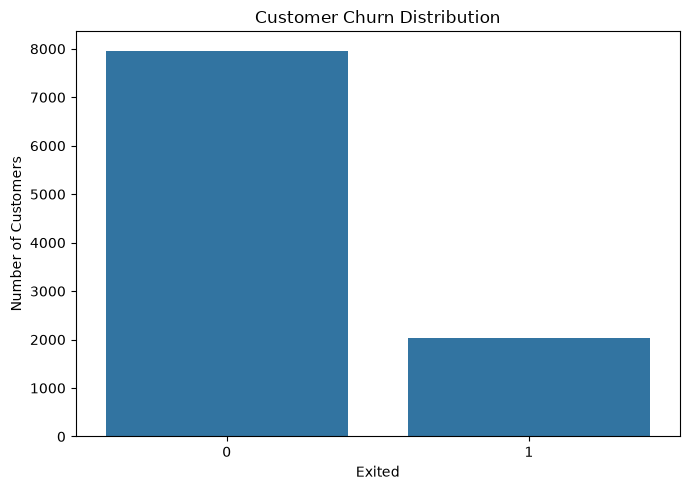

In [236]:
#Churn Count Visualization
plt.figure(figsize=(7, 5))

sns.countplot(
    data=analysis_df,
    x="Exited"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Exited")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [237]:
#Active vs Inactive Customers
activity_counts = (
    analysis_df["IsActiveMember"]
    .value_counts()
    .sort_index()
)

print(activity_counts)

IsActiveMember
0    4849
1    5151
Name: count, dtype: int64


In [238]:
#Active vs Inactive Churn
activity_churn = (
    analysis_df
    .groupby("IsActiveMember")["Exited"]
    .mean()
    * 100
)

print(activity_churn)

IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64


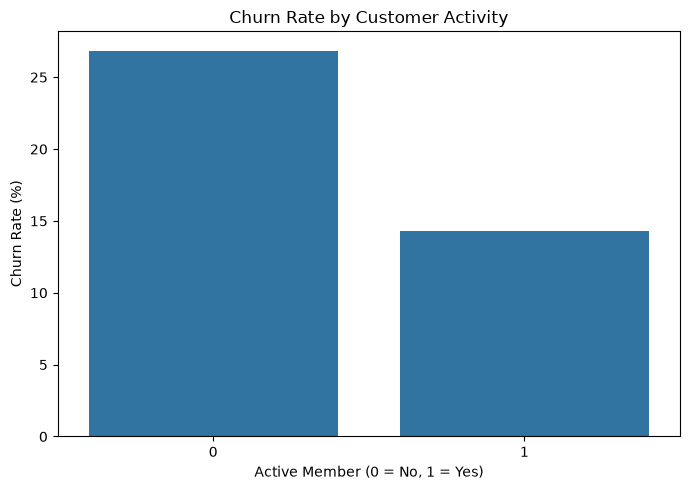

In [239]:
#Active vs Inactive Chart
plt.figure(figsize=(7, 5))

sns.barplot(
    x=activity_churn.index,
    y=activity_churn.values
)

plt.title("Churn Rate by Customer Activity")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/activity_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [240]:
#Create Engagement Profile
def create_engagement_profile(row):

    if row["IsActiveMember"] == 1 and row["NumOfProducts"] >= 2:
        return "Active Multi-Product"

    elif row["IsActiveMember"] == 1 and row["NumOfProducts"] == 1:
        return "Active Low-Product"

    elif row["IsActiveMember"] == 0 and row["Balance"] > 0:
        return "Inactive High-Balance"

    else:
        return "Inactive Low-Engagement"

In [241]:
#Apply Engagement Profile
analysis_df["EngagementProfile"] = (
    analysis_df.apply(
        create_engagement_profile,
        axis=1
    )
)

analysis_df["EngagementProfile"].value_counts()

EngagementProfile
Inactive High-Balance      3105
Active Multi-Product       2588
Active Low-Product         2563
Inactive Low-Engagement    1744
Name: count, dtype: int64

In [242]:
#Engagement Churn Table
engagement_churn = (
    analysis_df
    .groupby("EngagementProfile")["Exited"]
    .agg(["count", "mean"])
    .reset_index()
)

engagement_churn["ChurnRate"] = (
    engagement_churn["mean"] * 100
)

engagement_churn

,EngagementProfile,count,mean,ChurnRate
0,Active Low-Product,2563,0.189231,18.923137
1,Active Multi-Product,2588,0.096600,9.659969
2,Inactive High-Balance,3105,0.316264,31.626409
3,Inactive Low-Engagement,1744,0.183486,18.348624


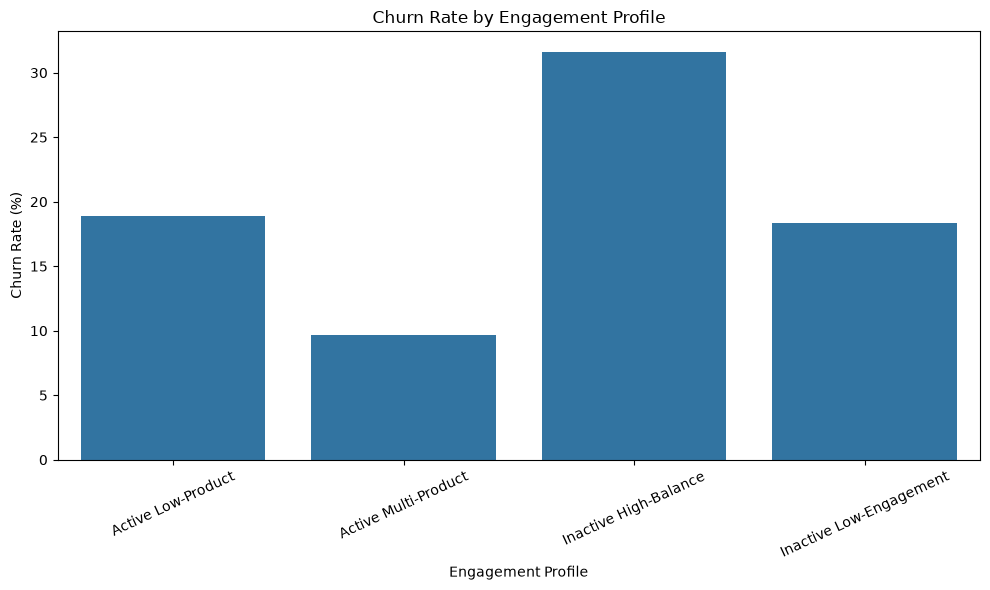

In [243]:
#Engagement Churn Chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=engagement_churn,
    x="EngagementProfile",
    y="ChurnRate"
)

plt.title("Churn Rate by Engagement Profile")
plt.xlabel("Engagement Profile")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=25)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/engagement_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [244]:
#Product Count Distribution
product_counts = (
    analysis_df["NumOfProducts"]
    .value_counts()
    .sort_index()
)

print(product_counts)

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64


In [245]:
#Product Count vs Churn
product_churn = (
    analysis_df
    .groupby("NumOfProducts")["Exited"]
    .agg(["count", "mean"])
    .reset_index()
)

product_churn["ChurnRate"] = (
    product_churn["mean"] * 100
)

product_churn

,NumOfProducts,count,mean,ChurnRate
0,1,5084,0.277144,27.714398
1,2,4590,0.075817,7.581699
2,3,266,0.827068,82.706767
3,4,60,1.000000,100.000000


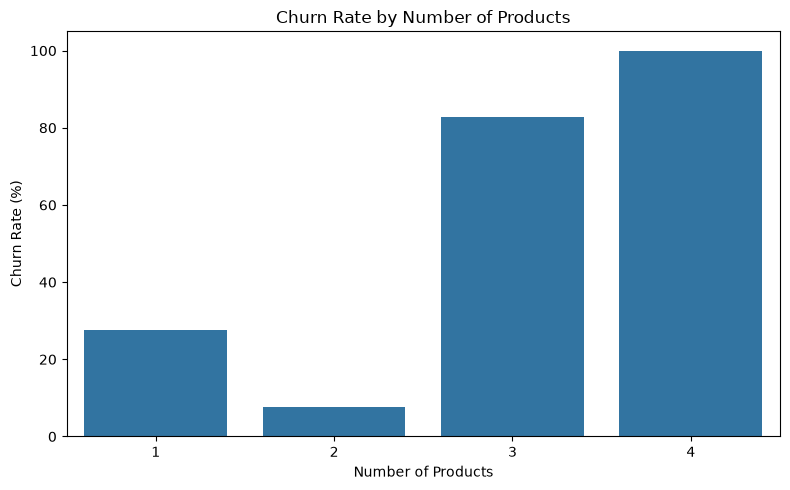

In [246]:
#Product Churn Chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=product_churn,
    x="NumOfProducts",
    y="ChurnRate"
)

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/product_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [247]:
#Single vs Multi Product
analysis_df["ProductDepth"] = np.where(
    analysis_df["NumOfProducts"] == 1,
    "Single Product",
    "Multi Product"
)

In [248]:
#Single vs Multi Product Churn
product_depth_churn = (
    analysis_df
    .groupby("ProductDepth")["Exited"]
    .agg(["count", "mean"])
    .reset_index()
)

product_depth_churn["ChurnRate"] = (
    product_depth_churn["mean"] * 100
)

product_depth_churn

,ProductDepth,count,mean,ChurnRate
0,Multi Product,4916,0.127746,12.774614
1,Single Product,5084,0.277144,27.714398


In [249]:
# Balance Tier

balance_bins = [
    -1,
    0,
    analysis_df["Balance"].quantile(0.25),
    analysis_df["Balance"].quantile(0.50),
    analysis_df["Balance"].quantile(0.75),
    analysis_df["Balance"].max()
]

# Remove duplicate bin edges
balance_bins = sorted(set(balance_bins))

balance_labels = [
    "Zero Balance",
    "Low Balance",
    "Medium Balance",
    "High Balance",
    "Very High Balance"
]

# Make labels match the number of intervals
balance_labels = balance_labels[:len(balance_bins) - 1]

analysis_df["BalanceTier"] = pd.cut(
    analysis_df["Balance"],
    bins=balance_bins,
    labels=balance_labels,
    include_lowest=True
)

analysis_df["BalanceTier"].value_counts(dropna=False)

BalanceTier
Zero Balance      3617
Medium Balance    2500
High Balance      2500
Low Balance       1383
Name: count, dtype: int64

In [250]:
#Balance vs Churn
balance_churn = (
    analysis_df
    .groupby("BalanceTier", observed=True)["Exited"]
    .mean()
    .reset_index()
)

balance_churn["ChurnRate"] = (
    balance_churn["Exited"] * 100
)

balance_churn

,BalanceTier,Exited,ChurnRate
0,Zero Balance,0.138236,13.823611
1,Low Balance,0.208243,20.824295
2,Medium Balance,0.262800,26.280000
3,High Balance,0.236800,23.680000


In [251]:
#High Value Threshold
balance_threshold = (
    analysis_df["Balance"].quantile(0.75)
)

salary_threshold = (
    analysis_df["EstimatedSalary"].quantile(0.75)
)

print("High balance threshold:", balance_threshold)
print("High salary threshold:", salary_threshold)

High balance threshold: 127644.24
High salary threshold: 149388.2475


In [252]:
#High Value Customer
analysis_df["HighValueCustomer"] = (
    (analysis_df["Balance"] >= balance_threshold) |
    (analysis_df["EstimatedSalary"] >= salary_threshold)
    
)

In [253]:
#Disengaged Customer
analysis_df["Disengaged"] = (
    analysis_df["IsActiveMember"] == 0
)

In [254]:
#High-Value Disengaged
analysis_df["HighValueDisengaged"] = (
    analysis_df["HighValueCustomer"] &
    analysis_df["Disengaged"]
)

In [255]:
#High-Value Disengaged Count
high_value_disengaged_count = (
    analysis_df["HighValueDisengaged"].sum()
)

print(
    "High-value disengaged customers:",
    high_value_disengaged_count
)

High-value disengaged customers: 2154


In [256]:
#High-Value Disengaged Churn
high_value_disengaged_churn = (
    analysis_df.loc[
        analysis_df["HighValueDisengaged"],
        "Exited"
    ].mean() * 100
)

print(
    f"High-value disengaged churn: "
    f"{high_value_disengaged_churn:.2f}%"
)

High-value disengaged churn: 29.06%


In [257]:
#Balance Salary Ratio
analysis_df["BalanceSalaryRatio"] = (
    analysis_df["Balance"] /
    analysis_df["EstimatedSalary"].replace(0, np.nan)
)

In [258]:
#Credit Card Analysis
credit_card_churn = (
    analysis_df
    .groupby("HasCrCard")["Exited"]
    .agg(["count", "mean"])
    .reset_index()
)

credit_card_churn["ChurnRate"] = (
    credit_card_churn["mean"] * 100
)

credit_card_churn

,HasCrCard,count,mean,ChurnRate
0,0,2945,0.208149,20.814941
1,1,7055,0.201843,20.184266


In [259]:
#Tenure Analysis
tenure_churn = (
    analysis_df
    .groupby("Tenure")["Exited"]
    .mean()
    .reset_index()
)

tenure_churn["ChurnRate"] = (
    tenure_churn["Exited"] * 100
)

tenure_churn

,Tenure,Exited,ChurnRate
0,0,0.230024,23.002421
1,1,0.224155,22.415459
2,2,0.191794,19.179389
3,3,0.211100,21.110010
4,4,0.205258,20.525784
5,5,0.206522,20.652174
6,6,0.202689,20.268873
7,7,0.172179,17.217899
8,8,0.192195,19.219512
9,9,0.216463,21.646341


In [260]:
#Age Groups
analysis_df["AgeGroup"] = pd.cut(
    analysis_df["Age"],
    bins=[0, 30, 40, 50, 60, 100],
    labels=[
        "<30",
        "30-40",
        "40-50",
        "50-60",
        "60+"
    ]
)

In [261]:
#Geography Churn
geography_churn = (
    analysis_df
    .groupby("Geography")["Exited"]
    .mean()
    .reset_index()
)

geography_churn["ChurnRate"] = (
    geography_churn["Exited"] * 100
)

geography_churn

,Geography,Exited,ChurnRate
0,France,0.161548,16.154767
1,Germany,0.324432,32.443204
2,Spain,0.166734,16.673395


In [262]:
#Relationship Strength
analysis_df["RelationshipStrength"] = (
    analysis_df["IsActiveMember"] * 40
    +
    (analysis_df["NumOfProducts"] >= 2).astype(int) * 30
    +
    analysis_df["HasCrCard"] * 15
    +
    (
        analysis_df["Tenure"] /
        analysis_df["Tenure"].max()
    ) * 15
)

In [263]:
#Relationship Tier
analysis_df["RelationshipTier"] = pd.cut(
    analysis_df["RelationshipStrength"],
    bins=[-1, 30, 60, 80, 100],
    labels=[
        "Weak",
        "Moderate",
        "Strong",
        "Very Strong"
    ]
)

In [264]:
#Relationship Strength vs Churn
relationship_churn = (
    analysis_df
    .groupby(
        "RelationshipTier",
        observed=True
    )["Exited"]
    .agg(["count", "mean"])
    .reset_index()
)

relationship_churn["ChurnRate"] = (
    relationship_churn["mean"] * 100
)

relationship_churn

,RelationshipTier,count,mean,ChurnRate
0,Weak,2545,0.364244,36.424361
1,Moderate,3731,0.180917,18.091664
2,Strong,1635,0.146789,14.678899
3,Very Strong,2089,0.093346,9.334610


In [265]:
#Retention Score
analysis_df["RetentionScore"] = (
    analysis_df["RelationshipStrength"]
)

In [266]:
#Retention Segment
analysis_df["RetentionSegment"] = pd.cut(
    analysis_df["RetentionScore"],
    bins=[-1, 30, 60, 80, 100],
    labels=[
        "Critical Risk",
        "Moderate Risk",
        "Stable",
        "Strong"
    ]
)

In [267]:
#Retention Segment Churn
retention_churn = (
    analysis_df
    .groupby(
        "RetentionSegment",
        observed=True
    )["Exited"]
    .agg(["count", "mean"])
    .reset_index()
)

retention_churn["ChurnRate"] = (
    retention_churn["mean"] * 100
)

retention_churn

,RetentionSegment,count,mean,ChurnRate
0,Critical Risk,2545,0.364244,36.424361
1,Moderate Risk,3731,0.180917,18.091664
2,Stable,1635,0.146789,14.678899
3,Strong,2089,0.093346,9.334610


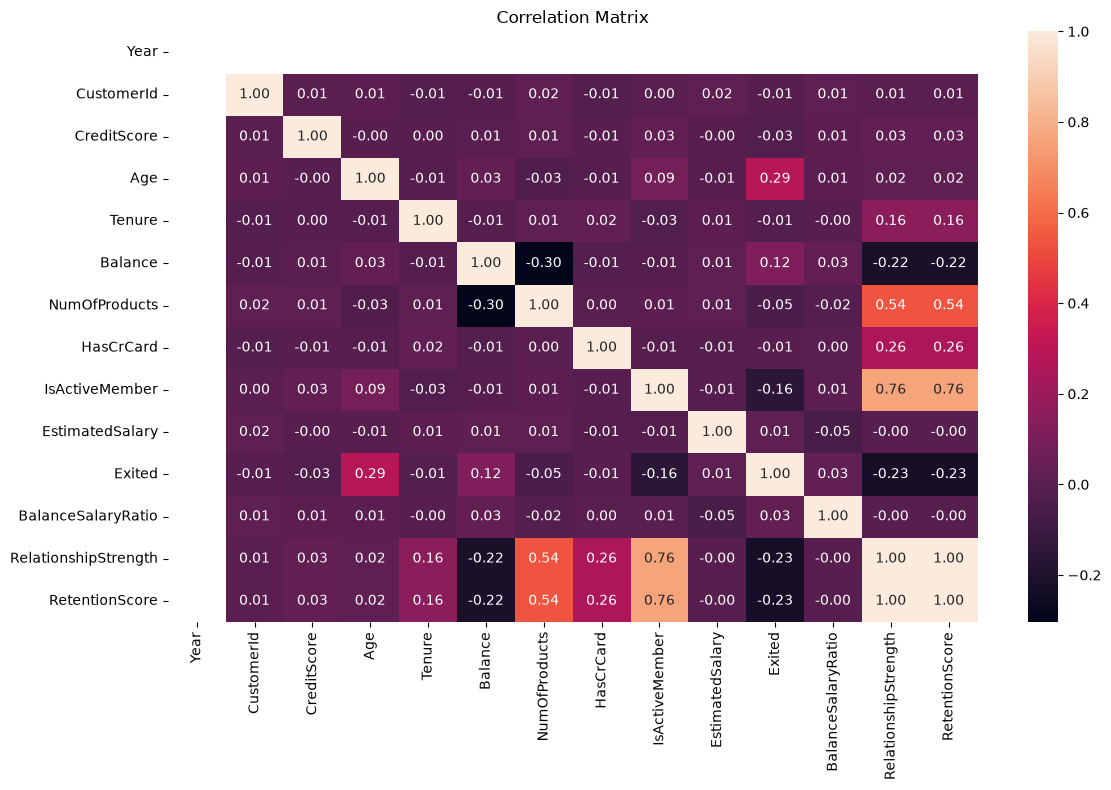

In [268]:
#Correlation Matrix
numeric_df = analysis_df.select_dtypes(
    include=np.number
)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [269]:
#Chi-Square: Activity vs Churn
activity_table = pd.crosstab(
    analysis_df["IsActiveMember"],
    analysis_df["Exited"]
)

chi2, p_value, dof, expected = (
    chi2_contingency(activity_table)
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 242.98534164287963
p-value: 8.785858269303703e-55


In [270]:
if p_value < 0.05:
    print(
        "Result: Statistically significant association "
        "between activity and churn."
    )
else:
    print(
        "Result: No statistically significant association "
        "between activity and churn."
    )

Result: Statistically significant association between activity and churn.


In [271]:
#Chi-Square: Product Depth vs Churn
product_table = pd.crosstab(
    analysis_df["ProductDepth"],
    analysis_df["Exited"]
)

chi2_product, p_product, dof_product, expected_product = (
    chi2_contingency(product_table)
)

print(
    "Chi-square statistic:",
    chi2_product
)

print(
    "p-value:",
    p_product
)

Chi-square statistic: 342.9844646598237
p-value: 1.4286160470013235e-76


In [272]:
#Select Features
features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary"
]

X = analysis_df[features]

y = analysis_df["Exited"]

In [273]:
#Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 8000
Testing rows: 2000


In [274]:
#Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

In [275]:
#Logistic Regression
model = LogisticRegression(
    max_iter=1000
)

model.fit(
    X_train_scaled,
    y_train
)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [276]:
#Predictions
y_pred = model.predict(
    X_test_scaled
)

y_probability = model.predict_proba(
    X_test_scaled
)[:, 1]

In [277]:
#Model Evaluation
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Accuracy : 0.8085
Precision: 0.6304
Recall   : 0.1425
F1 Score : 0.2325
ROC-AUC  : 0.7607


In [278]:
#Classification Report
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.82      0.98      0.89      1593
           1       0.63      0.14      0.23       407

    accuracy                           0.81      2000
   macro avg       0.72      0.56      0.56      2000
weighted avg       0.78      0.81      0.76      2000



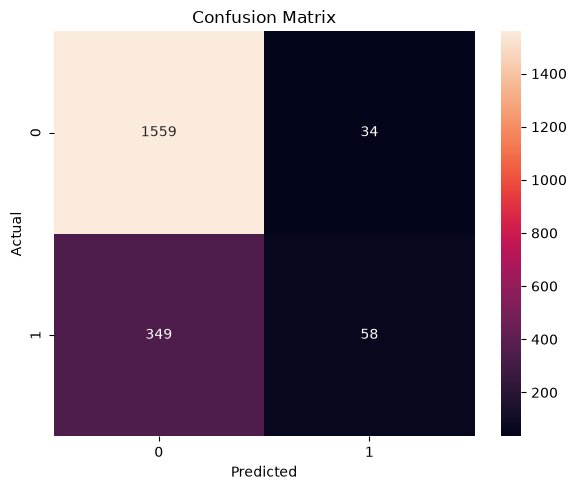

In [279]:
#Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [280]:
#Model Coefficients
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values(
    "Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient
1,Age,0.740225
3,Balance,0.314516
7,EstimatedSalary,0.052170
2,Tenure,-0.019931
4,NumOfProducts,-0.022240
5,HasCrCard,-0.026591
0,CreditScore,-0.080399
6,IsActiveMember,-0.523471


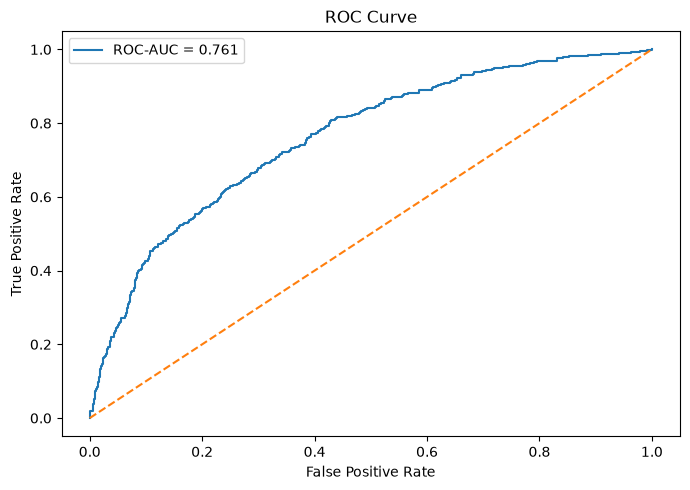

In [281]:
#ROC Curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.tight_layout()

plt.savefig(
    "../outputs/figures/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [282]:
#CREATE FINAL ANALYTICAL DATASET
final_columns = [
    "CustomerId",
    "Geography",
    "Gender",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited",
    "EngagementProfile",
    "ProductDepth",
    "BalanceTier",
    "BalanceSalaryRatio",
    "HighValueCustomer",
    "HighValueDisengaged",
    "RelationshipStrength",
    "RelationshipTier",
    "RetentionScore",
    "RetentionSegment"
]

final_df = analysis_df[
    final_columns
].copy()

final_df.head()

,CustomerId,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,...,EngagementProfile,ProductDepth,BalanceTier,BalanceSalaryRatio,HighValueCustomer,HighValueDisengaged,RelationshipStrength,RelationshipTier,RetentionScore,RetentionSegment
0,15634602,France,Female,42,2,0.00,1,1,1,101348.88,...,Active Low-Product,Single Product,Zero Balance,0.000000,False,False,58.0,Moderate,58.0,Moderate Risk
1,15647311,Spain,Female,41,1,83807.86,1,0,1,112542.58,...,Active Low-Product,Single Product,Low Balance,0.744677,False,False,41.5,Moderate,41.5,Moderate Risk
2,15619304,France,Female,42,8,159660.80,3,1,0,113931.57,...,Inactive High-Balance,Multi Product,High Balance,1.401375,True,True,57.0,Moderate,57.0,Moderate Risk
3,15701354,France,Female,39,1,0.00,2,0,0,93826.63,...,Inactive Low-Engagement,Multi Product,Zero Balance,0.000000,False,False,31.5,Moderate,31.5,Moderate Risk
4,15737888,Spain,Female,43,2,125510.82,1,1,1,79084.10,...,Active Low-Product,Single Product,Medium Balance,1.587055,False,False,58.0,Moderate,58.0,Moderate Risk


In [283]:
#Export Final Dataset
final_df.to_csv(
    "../outputs/customer_retention_analysis.csv",
    index=False
)

print(
    "Final analytical dataset saved successfully."
)

Final analytical dataset saved successfully.


In [284]:
#important tables
engagement_churn.to_csv(
    "../outputs/tables/engagement_churn.csv",
    index=False
)

product_churn.to_csv(
    "../outputs/tables/product_churn.csv",
    index=False
)

balance_churn.to_csv(
    "../outputs/tables/balance_churn.csv",
    index=False
)

relationship_churn.to_csv(
    "../outputs/tables/relationship_churn.csv",
    index=False
)

retention_churn.to_csv(
    "../outputs/tables/retention_churn.csv",
    index=False
)

coefficients.to_csv(
    "../outputs/tables/model_coefficients.csv",
    index=False
)